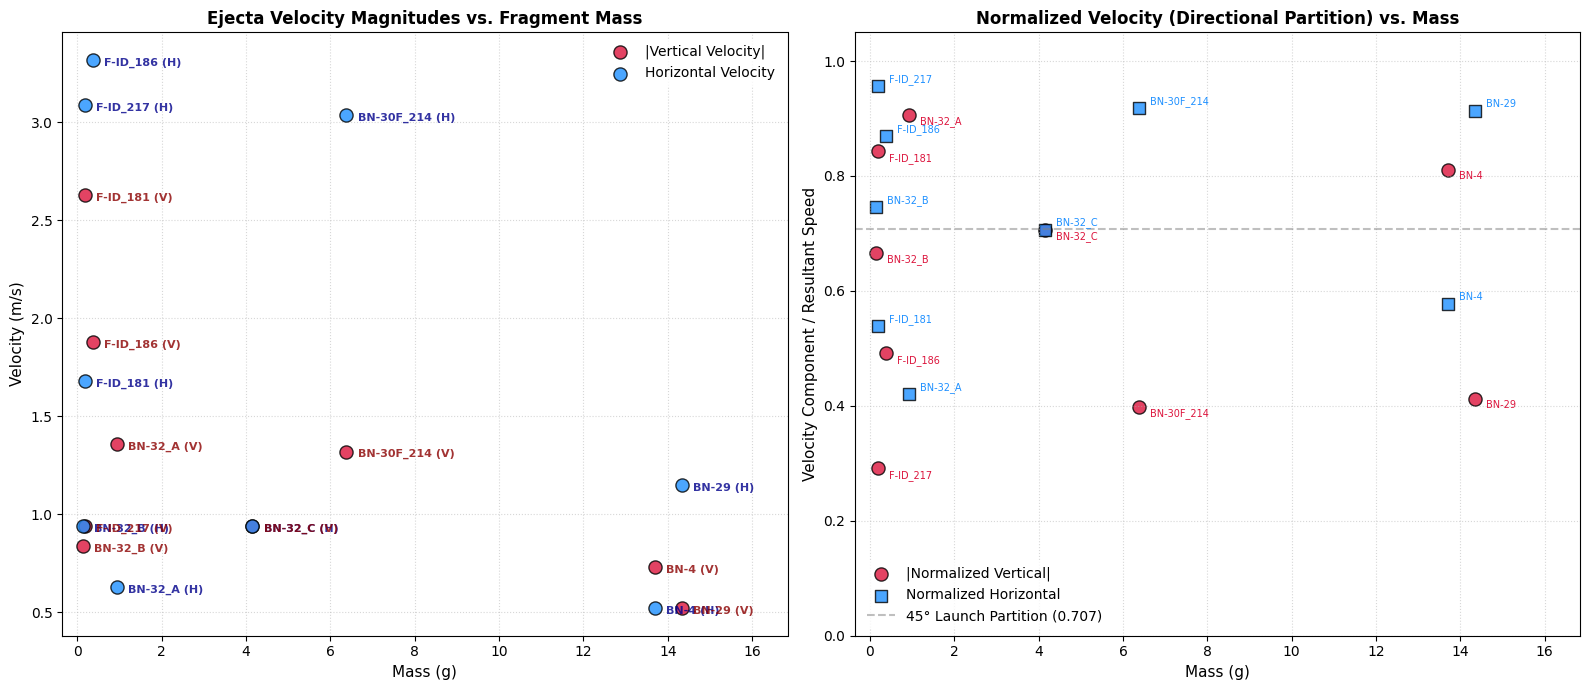

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Dataset from your experiment
data = {
    "Boulder": [
        "BN-29",
        "BN-30F_214",
        "BN-32_B",
        "BN-32_A",
        "BN-32_C",
        "BN-4",
        "F-ID_186",
        "F-ID_217",
        "F-ID_181",
    ],
    "Mass_g": [14.34, 6.38, 0.14, 0.93, 4.15, 13.70, 0.37, 0.18, 0.18],
    "Vertical_v": [-0.52, 1.32, -0.84, -1.36, -0.94, -0.73, 1.88, 0.94, 2.63],
    "Horizontal_v": [1.15, 3.04, 0.94, 0.63, 0.94, 0.52, 3.32, 3.09, 1.68],
    "Resultant_v": [1.26, 3.31, 1.26, 1.50, 1.33, 0.90, 3.82, 3.23, 3.12],
}

df = pd.DataFrame(data)

# 2. Calculate Normalized Velocities
df["Vertical_v_norm"] = df["Vertical_v"] / df["Resultant_v"]
df["Horizontal_v_norm"] = df["Horizontal_v"] / df["Resultant_v"]

# Sort by mass so data frame remains consistently organized
df = df.sort_values(by="Mass_g")

# 3. Plotting Setup
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# --- PLOT 1: Pure Scatter Plot of Raw Velocities (No Fit Line) ---
ax1.scatter(
    df["Mass_g"],
    df["Vertical_v"].abs(),
    color="crimson",
    s=90,
    edgecolors="k",
    label="|Vertical Velocity|",
    alpha=0.8,
    zorder=3,
)
ax1.scatter(
    df["Mass_g"],
    df["Horizontal_v"],
    color="dodgerblue",
    s=90,
    edgecolors="k",
    label="Horizontal Velocity",
    alpha=0.8,
    zorder=3,
)

# Dynamic labeling next to both horizontal and vertical markers
for i, txt in enumerate(df["Boulder"]):
    mx = df["Mass_g"].iloc[i]
    v_vert = abs(df["Vertical_v"].iloc[i])
    v_horiz = df["Horizontal_v"].iloc[i]

    # Label for Horizontal data point (Blue)
    ax1.annotate(
        f"{txt} (H)",
        (mx, v_horiz),
        textcoords="offset points",
        xytext=(8, -2),
        ha="left",
        va="center",
        fontsize=8,
        color="darkblue",
        weight="bold",
        alpha=0.8,
    )

    # Label for Vertical data point (Red)
    ax1.annotate(
        f"{txt} (V)",
        (mx, v_vert),
        textcoords="offset points",
        xytext=(8, -2),
        ha="left",
        va="center",
        fontsize=8,
        color="darkred",
        weight="bold",
        alpha=0.8,
    )

ax1.set_title(
    "Ejecta Velocity Magnitudes vs. Fragment Mass",
    fontsize=12,
    fontweight="bold",
)
ax1.set_ylabel("Velocity (m/s)", fontsize=11)
ax1.set_xlabel("Mass (g)", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend(frameon=True, facecolor="white", edgecolor="none")
ax1.set_xlim(df["Mass_g"].min() - 0.5, df["Mass_g"].max() + 2.5)

# --- PLOT 2: Pure Scatter Plot of Normalized Velocities ---
ax2.scatter(
    df["Mass_g"],
    df["Vertical_v_norm"].abs(),
    color="crimson",
    marker="o",
    s=90,
    edgecolors="k",
    label="|Normalized Vertical|",
    alpha=0.8,
)
ax2.scatter(
    df["Mass_g"],
    df["Horizontal_v_norm"],
    color="dodgerblue",
    marker="s",
    s=80,
    edgecolors="k",
    label="Normalized Horizontal",
    alpha=0.8,
)

# Labeling for the Normalized Plot
for i, txt in enumerate(df["Boulder"]):
    mx = df["Mass_g"].iloc[i]
    vn_vert = abs(df["Vertical_v_norm"].iloc[i])
    vn_horiz = df["Horizontal_v_norm"].iloc[i]

    ax2.annotate(
        txt,
        (mx, vn_horiz),
        textcoords="offset points",
        xytext=(8, 3),
        fontsize=7,
        color="dodgerblue",
    )
    ax2.annotate(
        txt,
        (mx, vn_vert),
        textcoords="offset points",
        xytext=(8, -7),
        fontsize=7,
        color="crimson",
    )

# Baseline reference line at 0.707 (where horizontal equals vertical at 45 degrees)
ax2.axhline(
    0.707,
    color="gray",
    linestyle="--",
    alpha=0.5,
    label="45° Launch Partition (0.707)",
)

ax2.set_title(
    "Normalized Velocity (Directional Partition) vs. Mass",
    fontsize=12,
    fontweight="bold",
)
ax2.set_ylabel("Velocity Component / Resultant Speed", fontsize=11)
ax2.set_xlabel("Mass (g)", fontsize=11)
ax2.set_ylim(0, 1.05)
ax2.set_xlim(df["Mass_g"].min() - 0.5, df["Mass_g"].max() + 2.5)
ax2.grid(True, linestyle=":", alpha=0.5)
ax2.legend(frameon=True, facecolor="white", edgecolor="none")

plt.tight_layout()
plt.show()

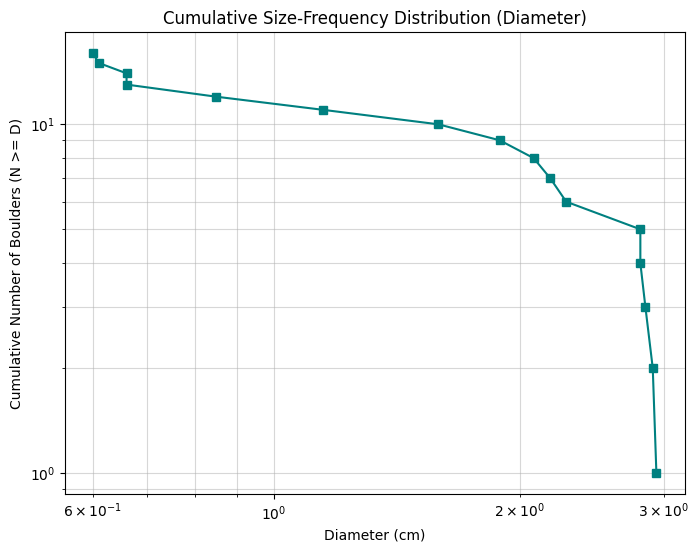

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Your diameter data
diameters = np.array([2.85, 2.18, 0.61, 1.15, 1.89, 2.81, 0.85, 0.66, 
                      0.66, 1.59, 0.60, 2.08, 2.28, 2.81, 2.91, 2.94])

# 1. Sort the data in descending order
sorted_d = np.sort(diameters)[::-1]

# 2. Create the cumulative count (N >= D)
cumulative_n = np.arange(1, len(sorted_d) + 1)

# 3. Plotting on a Log-Log scale
plt.figure(figsize=(8, 6))
plt.loglog(sorted_d, cumulative_n, marker='s', linestyle='-', color='teal', markersize=6)

plt.title('Cumulative Size-Frequency Distribution (Diameter)')
plt.xlabel('Diameter (cm)')
plt.ylabel('Cumulative Number of Boulders (N >= D)')
plt.grid(True, which="both", ls="-", alpha=0.5)

plt.show()

plt.show()

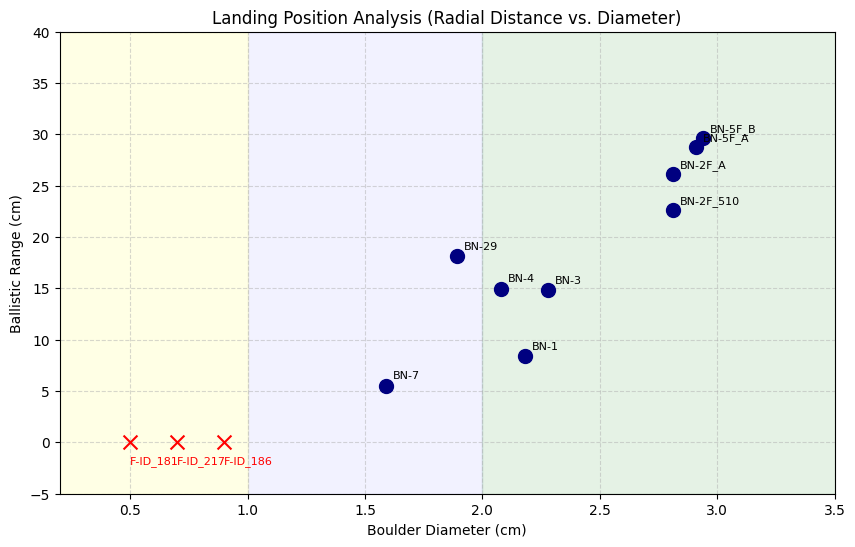

In [ ]:
import matplotlib.pyplot as plt

# Aligned Data
names = ['BN-5F_B', 'BN-5F_A', 'BN-2F_510', 'BN-2F_A', 'BN-3', 'BN-1', 'BN-4', 'BN-29', 'BN-7', 'F-ID_186', 'F-ID_217', 'F-ID_181','BN-30F','BN-32_B','BN-32_A','BN-32']
diameters = [1.59, 0.60, 2.08, 2.28, 2.81, 2.91, 2.81, 2.85, 2.94, 0.85, 0.66, 0.66,2.18,0.61,1.15,1.89]
distances = [29.62, 28.74, 22.59, 26.13, 14.82, 8.39, 14.96, 18.16, 5.51, 0, 0, 0]
status = ['Located', 'Located', 'Located', 'Located', 'Located', 'Located', 'Located', 'Located', 'Located', 'Unlocated', 'Unlocated', 'Unlocated']

plt.figure(figsize=(10, 6))

# Background Zones
plt.axvspan(0, 1.0, color='yellow', alpha=0.1, label='Fragments')
plt.axvspan(1.0, 2.0, color='blue', alpha=0.05, label='Intermediate')
plt.axvspan(2.0, 4.0, color='green', alpha=0.1, label='Boulders')

# Plotting
for i in range(len(names)):
    if status[i] == 'Located':
        plt.scatter(diameters[i], distances[i], color='navy', s=100, zorder=3)
        plt.annotate(names[i], (diameters[i], distances[i]), xytext=(5, 5), textcoords='offset points', fontsize=8)
    else:
        plt.scatter(diameters[i], distances[i], color='red', marker='x', s=100, zorder=3)
        plt.annotate(names[i], (diameters[i], distances[i]), xytext=(0, -15), textcoords='offset points', fontsize=8, color='red')

plt.title('Landing Position Analysis (Radial Distance vs. Diameter)')
plt.xlabel('Boulder Diameter (cm)')
plt.ylabel('Ballistic Range (cm)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(0.2, 3.5)
plt.ylim(-5, 40)
plt.show()